# 11. Heat transfer: transient conduction at short and long times

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1, 3 and 5

A slab at uniform temperature has its faces suddenly raised to a new temperature.
The textbook answer is a Fourier series, which converges quickly once the heat has
reached the centre and slowly before that. The method of images gives a second exact
answer, a series of error functions, which converges quickly at short times and slowly
at long ones. Each series is an expansion about one end of the time axis: at short
times the slab behaves like two independent semi-infinite solids, and at long times
only the slowest mode survives. This chapter shows how the two expansions divide the
work, where they are equally good, and what their leading terms, which are the basis
of the familiar engineering charts, miss. It also has a physical example of terms
beyond all orders (Chapter 3): at short times the temperature at the centre has an
expansion in powers of $t$ whose terms are all zero.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
from scipy.special import erfc

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 30

## 11.1 Two exact solutions

Take a slab $-L < x < L$ at temperature $T_0$, with both faces held at $T_1$ from
$t = 0$. With $\theta = (T - T_0)/(T_1 - T_0)$, lengths in units of $L$ and time in
units of $L^2/\kappa$ (so that $t$ is the Fourier number), the problem is

$$ \theta_t = \theta_{xx} , \qquad \theta(\pm1, t) = 1 , \qquad \theta(x, 0) = 0 . $$

Separation of variables gives the Fourier series

$$ \theta = 1 - \sum_{n=0}^{\infty}\frac{4(-1)^n}{(2n+1)\pi}
   \cos\frac{(2n+1)\pi x}{2}\; e^{-(2n+1)^2\pi^2 t/4} , $$

whose terms decay like $e^{-(2n+1)^2\pi^2t/4}$. The method of images builds the same
solution from semi-infinite solids, each face's solution $\operatorname{erfc}$ being
corrected by reflections from the opposite face:

$$ \theta = \sum_{n=0}^{\infty}(-1)^n\left[\operatorname{erfc}\frac{2n+1-x}{2\sqrt t}
   + \operatorname{erfc}\frac{2n+1+x}{2\sqrt t}\right] , $$

whose terms decay like $e^{-(2n+1)^2/4t}$. The two series are related by the Poisson
summation formula, the identity behind the transformation of theta functions. We
check that they agree and use them, in high precision and with many terms, as the
reference.

In [2]:
def theta_images(x, t, N):
    s = 2 * mp.sqrt(t)
    return mp.fsum((-1) ** n * (mp.erfc((2 * n + 1 - x) / s) + mp.erfc((2 * n + 1 + x) / s)) for n in range(N))


def theta_fourier(x, t, N):
    return 1 - mp.fsum(4 * (-1) ** n / ((2 * n + 1) * mp.pi) * mp.cos((2 * n + 1) * mp.pi * x / 2)
                       * mp.exp(-(2 * n + 1) ** 2 * mp.pi**2 * t / 4) for n in range(N))


for t in (0.01, 0.3, 2.0):
    a, b = theta_images(0, t, 60), theta_fourier(0, t, 60)
    print(f"t = {t}: centre temperature {mp.nstr(a, 15)}; images - Fourier = {mp.nstr(a - b, 2)}")

ts = np.logspace(-2, math.log10(2), 60)
centre = np.array([float(theta_images(0, t, 60)) for t in ts])

t = 0.01: centre temperature 3.07491958885607e-12; images - Fourier = -9.8e-32
t = 0.3: centre temperature 0.393196182780912; images - Fourier = 4.9e-32
t = 2.0: centre temperature 0.990843009710239; images - Fourier = 9.9e-32


## 11.2 Truncating each series

Truncated after $N$ terms, the Fourier series has an error of about
$e^{-(2N+1)^2\pi^2t/4}$, and the image series an error of about
$e^{-(2N+1)^2/4t}$. The first is small when $t$ is large, the second when $t$ is
small, and the exponents are equal when

$$ \frac{\pi^2 t}{4} = \frac{1}{4t} , \qquad t = \frac1\pi \approx 0.32 . $$

At this Fourier number the two series converge equally fast; below it the images
win, above it the modes. Either way a few terms give full double precision.

In [3]:
def fourier_np(x, t, N):
    n = np.arange(N)[:, None]
    return 1 - np.sum(4 * (-1.0) ** n / ((2 * n + 1) * np.pi) * np.cos((2 * n + 1) * np.pi * x / 2)
                      * np.exp(-(2 * n + 1) ** 2 * np.pi**2 * t / 4), axis=0)


def images_np(x, t, N):
    n = np.arange(N)[:, None]
    s = 2 * np.sqrt(t)
    return np.sum((-1.0) ** n * (erfc((2 * n + 1 - x) / s) + erfc((2 * n + 1 + x) / s)), axis=0)


err_f = {N: np.abs(fourier_np(0, ts, N) - centre) for N in (1, 2, 3)}
err_i = {N: np.abs(images_np(0, ts, N) - centre) for N in (1, 2, 3)}
for N in (1, 2, 3):
    k = np.argmin(np.abs(ts - 1 / math.pi))
    print(f"N = {N}: at t = {ts[k]:.3f}, Fourier error {err_f[N][k]:.1e}, images error {err_i[N][k]:.1e},"
          f" exp(-(2N+1)^2 pi/4) = {math.exp(-(2 * N + 1) ** 2 * math.pi / 4):.1e}")
need = {}
for name, fn in (("Fourier", fourier_np), ("images", images_np)):
    need[name] = [next(N for N in range(1, 400) if abs(fn(0, np.array([t]), N)[0] - c) < 1e-12)
                  for t, c in zip(ts, centre)]
for t in (0.01, 0.05, 0.32, 1.0):
    k = np.argmin(np.abs(ts - t))
    print(f"t = {ts[k]:.3f}: terms for 1e-12 at the centre: Fourier {need['Fourier'][k]:3d}, images {need['images'][k]}")

N = 1: at t = 0.332, Fourier error 2.7e-04, images error 4.6e-04, exp(-(2N+1)^2 pi/4) = 8.5e-04
N = 2: at t = 0.332, Fourier error 3.3e-10, images error 1.7e-09, exp(-(2N+1)^2 pi/4) = 3.0e-09
N = 3: at t = 0.332, Fourier error 0.0e+00, images error 3.3e-16, exp(-(2N+1)^2 pi/4) = 1.9e-17
t = 0.010: terms for 1e-12 at the centre: Fourier  16, images 1
t = 0.050: terms for 1e-12 at the centre: Fourier   7, images 1
t = 0.332: terms for 1e-12 at the centre: Fourier   3, images 3
t = 0.975: terms for 1e-12 at the centre: Fourier   2, images 5


Near $t = 1/\pi$ both series need three terms for $10^{-12}$; at $t = 0.01$ the
Fourier series needs 16 terms and the image series one, and at $t = 1$ the order is
reversed. The engineering literature
keeps only the first term of each. The first Fourier mode is the "one-term
approximation" behind the Heisler charts, usually recommended for $t > 0.2$; the
first pair of images is the semi-infinite solid, used for short times.

In [4]:
for t in (0.05, 0.1, 0.2, 0.3, 0.5):
    ex = float(theta_images(0, t, 60))
    one = 1 - 4 / math.pi * math.exp(-math.pi**2 * t / 4)
    semi = 2 * math.erfc(1 / (2 * math.sqrt(t)))
    print(f"t = {t:4.2f}: centre theta = {ex:.5f}; one mode: rel. error of 1 - theta {(one - ex) / (1 - ex):+.1e};"
          f" semi-infinite: rel. error of theta {(semi - ex) / ex:+.1e}")

t = 0.05: centre theta = 0.00313; one mode: rel. error of 1 - theta -1.3e-01; semi-infinite: rel. error of theta -8.3e-16
t = 0.10: centre theta = 0.05069; one mode: rel. error of 1 - theta -4.8e-02; semi-infinite: rel. error of theta +7.8e-10
t = 0.20: centre theta = 0.22769; one mode: rel. error of 1 - theta -6.5e-03; semi-infinite: rel. error of theta +1.8e-05
t = 0.30: centre theta = 0.39320; one mode: rel. error of 1 - theta -8.9e-04; semi-infinite: rel. error of theta +5.5e-04
t = 0.50: centre theta = 0.62922; one mode: rel. error of 1 - theta -1.7e-05; semi-infinite: rel. error of theta +8.6e-03


At $t = 0.2$ the one-term Fourier approximation misses the centre temperature
difference $1 - \theta$ by 0.7 %, and by 5 % at $t = 0.1$; the semi-infinite solution
is good to $2\times10^{-5}$ at $t = 0.2$ and to 1 % at $t = 0.5$. Between them, the two
one-term formulas give the centre temperature on the whole time axis with an error in
$\theta$ below $10^{-3}$, if one switches near $t = 0.3$.

## 11.3 Beyond all orders: the centre at short times

At short times the centre temperature is

$$ \theta(0, t) \approx 2\operatorname{erfc}\frac{1}{2\sqrt t}
   \approx \frac{4}{\sqrt\pi}\sqrt t\;e^{-1/4t} . $$

Every derivative of this with respect to $t$ vanishes at $t = 0$, so its Taylor
series is identically zero: the heat arriving at the centre lies beyond all orders of
any power series in $t$, as $e^{-1/x}$ did in Chapter 3. Physically, the heat has
spread only a distance of order $\sqrt t$, and the centre is $1/\sqrt t$ such
distances away. For a slab of food 4 cm thick ($L = 2$ cm, $\kappa \approx
1.4\times10^{-7}$ m²/s, close to that of water), the time unit $L^2/\kappa$ is about
48 min; after 2.4 min ($t = 0.05$) the centre has risen by 0.3 % of the imposed step.

The heat taken up shows the same structure. The mean temperature, the fraction of
the final heat content already absorbed, is

$$ \bar\theta = 1 - \sum_{n\ge0}\frac{8}{(2n+1)^2\pi^2}e^{-(2n+1)^2\pi^2t/4}
   = 2\sqrt{\frac t\pi} + 4\sqrt t\sum_{n\ge1}(-1)^n\operatorname{ierfc}\frac{n}{\sqrt t} , $$

with $\operatorname{ierfc}z = e^{-z^2}/\sqrt\pi - z\operatorname{erfc}z$. The
semi-infinite result $2\sqrt{t/\pi}$ is therefore correct to all orders in $t$; its
error, about $2t^{3/2}e^{-1/t}/\sqrt\pi$, becomes noticeable only when the two
diffusion fronts meet in the middle and begin to interfere.

In [5]:
ierfc = lambda z: mp.exp(-z**2) / mp.sqrt(mp.pi) - z * mp.erfc(z)
mean_exact = lambda t: 1 - mp.fsum(8 / ((2 * n + 1) ** 2 * mp.pi**2) * mp.exp(-(2 * n + 1) ** 2 * mp.pi**2 * t / 4)
                                   for n in range(400))
mean_ts = np.logspace(-1.7, math.log10(2), 50)
mean_ex = np.array([float(mean_exact(t)) for t in mean_ts])
mean_semi_err = np.abs(2 * np.sqrt(mean_ts / np.pi) / mean_ex - 1)
mean_one_err = np.abs((1 - 8 / np.pi**2 * np.exp(-np.pi**2 * mean_ts / 4)) / mean_ex - 1)
for t in (0.02, 0.05, 0.1, 0.2):
    e = 2 * mp.sqrt(t / mp.pi) - mean_exact(t)
    print(f"t = {t:4.2f}: error of 2 sqrt(t/pi) = {mp.nstr(e, 4)};"
          f" ratio to 4 sqrt(t) ierfc(1/sqrt t) = {mp.nstr(e / (4 * mp.sqrt(t) * ierfc(1 / mp.sqrt(t))), 12)}")

t = 0.02: error of 2 sqrt(t/pi) = 5.98e-25; ratio to 4 sqrt(t) ierfc(1/sqrt t) = 1.00000029557
t = 0.05: error of 2 sqrt(t/pi) = 2.426e-11; ratio to 4 sqrt(t) ierfc(1/sqrt t) = 1.0
t = 0.10: error of 2 sqrt(t/pi) = 1.423e-6; ratio to 4 sqrt(t) ierfc(1/sqrt t) = 1.0
t = 0.20: error of 2 sqrt(t/pi) = 0.0005387; ratio to 4 sqrt(t) ierfc(1/sqrt t) = 0.999999909924


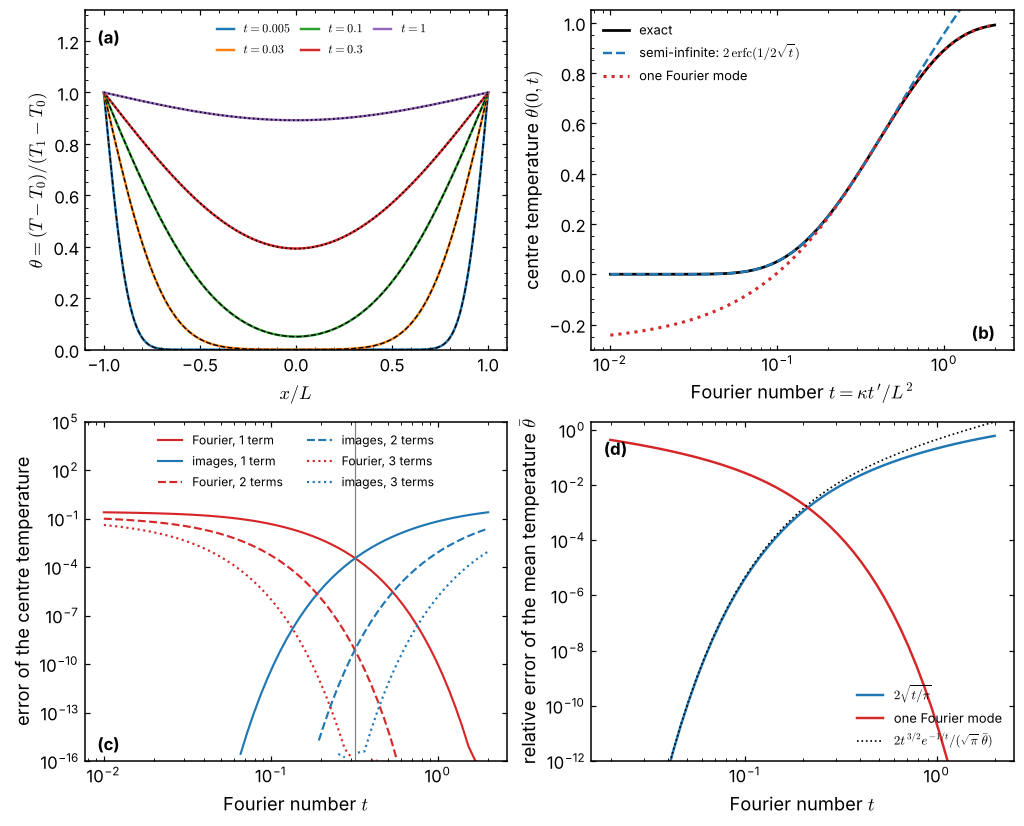

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
xs = np.linspace(-1, 1, 201)
for t, c in zip((0.005, 0.03, 0.1, 0.3, 1.0), ("C0", "C1", "C2", "C3", "C4")):
    ex = np.array([float(theta_images(x, t, 40)) for x in xs])
    ax.plot(xs, ex, color=c, lw=1.6, label=f"$t = {t:g}$")
    if t <= 0.1:
        ax.plot(xs, images_np(xs, np.full_like(xs, t), 1), "k--", lw=0.9)
    else:
        ax.plot(xs, fourier_np(xs, np.full_like(xs, t), 1), "k:", lw=1.1)
ax.set_xlabel("$x/L$"); ax.set_ylabel(r"$\theta = (T - T_0)/(T_1 - T_0)$")
ax.set_ylim(0, 1.32); ax.legend(loc="upper center", bbox_to_anchor=(0.56, 1.0), ncol=3, fontsize=8,
                                 handlelength=1.4, columnspacing=0.9)
am.panel_label(ax, "(a)")

ax = axes[0, 1]
ax.plot(ts, centre, "k", lw=1.8, label="exact")
ax.plot(ts, 2 * erfc(1 / (2 * np.sqrt(ts))), "C0--", label=r"semi-infinite: $2\,\mathrm{erfc}(1/2\sqrt{t})$")
ax.plot(ts, 1 - 4 / np.pi * np.exp(-np.pi**2 * ts / 4), "C3:", lw=2, label="one Fourier mode")
ax.set_xscale("log"); ax.set_ylim(-0.3, 1.05)
ax.set_xlabel("Fourier number $t = \\kappa t'/L^2$"); ax.set_ylabel("centre temperature $\\theta(0, t)$")
ax.legend(loc="upper left", fontsize=8.5); am.panel_label(ax, "(b)", y=0.08, x=0.9)

ax = axes[1, 0]
for N, ls in zip((1, 2, 3), ("-", "--", ":")):
    ax.semilogy(ts, np.where(err_f[N] > 1e-16, err_f[N], np.nan), "C3", ls=ls, lw=1.4,
                label=f"Fourier, {N} term" + ("s" if N > 1 else ""))
    ax.semilogy(ts, np.where(err_i[N] > 1e-16, err_i[N], np.nan), "C0", ls=ls, lw=1.4,
                label=f"images, {N} term" + ("s" if N > 1 else ""))
ax.axvline(1 / math.pi, color="0.5", lw=0.8)
ax.set_xscale("log"); ax.set_ylim(1e-16, 1e5)
ax.set_xlabel("Fourier number $t$"); ax.set_ylabel("error of the centre temperature")
ax.legend(loc="upper center", ncol=2, fontsize=8); am.panel_label(ax, "(c)", y=0.08)

ax = axes[1, 1]
ax.loglog(mean_ts, mean_semi_err, "C0", lw=1.6, label=r"$2\sqrt{t/\pi}$")
ax.loglog(mean_ts, mean_one_err, "C3", lw=1.6, label="one Fourier mode")
guide = 2 * mean_ts**1.5 * np.exp(-1 / mean_ts) / math.sqrt(math.pi) / mean_ex
ax.loglog(mean_ts, guide, "k:", lw=1.1, label=r"$2t^{3/2}e^{-1/t}/(\sqrt{\pi}\,\bar\theta)$")
ax.set_ylim(1e-12, 2)
ax.set_xlabel("Fourier number $t$"); ax.set_ylabel(r"relative error of the mean temperature $\bar\theta$")
ax.legend(loc="lower right", fontsize=8.5); am.panel_label(ax, "(d)")
plt.show()

**(a)** Temperature profiles (coloured), with the first pair of images (dashed,
$t \le 0.1$) and the first Fourier mode (dotted, $t \ge 0.3$). **(b)** Centre
temperature and its two one-term approximations. **(c)** Error of the centre
temperature when each series is truncated after one, two and three terms; the
grey line marks $t = 1/\pi$, where the two series converge equally fast. **(d)**
Relative error of the two one-term approximations to the mean temperature; the
dotted line is the leading term beyond all orders.

## Summary

* The slab problem has two exact series: images (fast at short times) and Fourier
  modes (fast at long times). They are expansions about the two ends of the time axis,
  related by Poisson summation, and equally fast at $t = 1/\pi$.
* The first term of each is the standard engineering approximation: the
  semi-infinite solid and the one-term (Heisler) solution. Switching from one to the
  other near $t = 0.3$ keeps the error of the centre temperature below $10^{-3}$.
* At short times the centre temperature and the correction to the heat uptake
  $2\sqrt{t/\pi}$ are of order $e^{-1/4t}$ and $e^{-1/t}$: invisible to any power
  series in $t$.

## Suggested references

* H. S. Carslaw and J. C. Jaeger, *Conduction of Heat in Solids*, 2nd ed.
  (Oxford University Press, 1959).
* J. Crank, *The Mathematics of Diffusion*, 2nd ed. (Oxford University Press, 1975).
* T. L. Bergman, A. S. Lavine, F. P. Incropera and D. P. DeWitt, *Fundamentals of
  Heat and Mass Transfer*, 7th ed. (Wiley, 2011).

## Exercises

1. Derive the image series by superposing semi-infinite solutions, and check that it
   satisfies both boundary conditions.
2. Use the Poisson summation formula to turn the image series into the Fourier series.
3. Find the short-time and long-time forms of the heat flux through a face, and the
   Fourier number at which they are equally accurate.
4. Repeat the analysis for a sphere of radius $R$ with its surface held at $T_1$. What
   replaces $2\sqrt{t/\pi}$ for the heat uptake at short times, and what is its first
   correction in powers of $\sqrt t$?

---

**Previous:** [10. Chemical physics: Kramers' escape rate](10_kramers_escape_rate.ipynb)